# JigNet Evaluation Script

Evaluates a trained **JigNet** on a folder of full images.

**Inputs (set in the Configuration cell):** `IMAGE_FOLDER`, `GRID_SIZE`, `MODEL_PATH`

**Pipeline per image**
1. Split the image into `GRID_SIZE x GRID_SIZE` tiles and prepare them (RGB, resize to 128x128, ToTensor, Normalize with the training mean/std).
2. Store each tile's true grid position, from which the true adjacency relation of every pair is derived.
3. Build all `N * (N-1)` ordered tile pairs (`N = GRID_SIZE^2`) and score each with JigNet (5 scores per pair).
4. Take the top-1 and top-3 labels per pair and check them against the ground truth.
5. Report per-class accuracy and the number of correctly recovered relationships for the image.

**After all images:** overall top-1 / top-3 accuracy, confusion matrix, and per-class precision / recall / F1.

> **Label convention.** Class ids, names and the meaning of each direction are defined in the Configuration cell (`LABEL_NAMES`, `DELTAS`). Check them against how your training `pairs.csv` was generated. The final cell can help detect a mismatch.

### 1. Mount Google Drive

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    print("Not running on Colab - skipping Drive mount.")

Mounted at /content/drive


### 2. Imports & device

In [ ]:
import os
import glob
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torchvision import transforms
from sklearn.metrics import confusion_matrix, classification_report, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


### 3. Configuration

The three main inputs are at the top. Everything else should match the training notebook.

In [ ]:
# ======================= MAIN INPUTS =======================
IMAGE_FOLDER = "/content/drive/MyDrive/Jigsaw_Puzzle_Project/jigsaw_dataset/COCO/resized_images"        # folder with full (unsplit) images
GRID_SIZE    = 6                                                                  # image is split into GRID_SIZE x GRID_SIZE tiles
MODEL_PATH   = "/content/drive/MyDrive/Jigsaw_Puzzle_Project/final_model/jignet_weights.pth"  # state_dict, training checkpoint, or full model
# ===========================================================

# Where to save per-pair / per-image CSVs and plots (set to None to skip saving)
OUTPUT_DIR = "/content/drive/MyDrive/Jigsaw_Puzzle_Project/eval_results"

# ---- Preprocessing (must match training) ----
TILE_SIZE = 128   # JigNet expects (3, 128, 128) tiles
MEAN = [0.5452349781990051, 0.6246451139450073, 0.4715678095817566]
STD  = [0.23454082012176514, 0.19042210280895233, 0.21782392263412476]

# ---- Labels ----
# Class id -> name. Index 0 is treated as NO_MATCH because the training class weights
# ([0.3, 2.4, 2.4, 2.4, 2.4]) down-weight class 0 as the dominant class.
LABEL_NAMES = {0: "NO_MATCH", 1: "LEFT", 2: "RIGHT", 3: "UP", 4: "DOWN"}

# For a pair (A, B): where is tile B relative to tile A?  class id -> (d_row, d_col)
# e.g. LEFT = B sits directly to the left of A.
DELTAS = {1: (0, -1), 2: (0, 1), 3: (-1, 0), 4: (1, 0)}
NO_MATCH = 0

# ---- Misc ----
PAIR_BATCH_SIZE = 512
TOP_K = 3
VERBOSE_PER_IMAGE = True
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

NUM_CLASSES = len(LABEL_NAMES)
CLASS_IDS = list(range(NUM_CLASSES))
CLASS_STR = [LABEL_NAMES[i] for i in CLASS_IDS]

if OUTPUT_DIR:
    os.makedirs(OUTPUT_DIR, exist_ok=True)

### 4. JigNet architecture (identical to the training notebook)

In [ ]:
class JigEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(kernel_size=2),

            nn.AdaptiveAvgPool2d(output_size=(2, 2)),
            nn.Flatten()
        )

    def forward(self, x):
        return self.encoder(x)


class JigNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.encoder = JigEncoder()
        feature_dim = 512
        combined_dim = feature_dim * 4

        self.mlp = nn.Sequential(
            nn.Linear(combined_dim, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(p=0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, tile_a, tile_b):
        feature_a = self.encoder(tile_a)
        feature_b = self.encoder(tile_b)
        diff = torch.abs(feature_a - feature_b)
        prod = feature_a * feature_b
        combined = torch.cat([feature_a, feature_b, diff, prod], dim=1)
        return self.mlp(combined)

### 5. Load the model

In [ ]:
def load_jignet(model_path, device):
    """Accepts a bare state_dict, a training checkpoint (with 'model_state_dict'), or a fully pickled model."""
    try:
        obj = torch.load(model_path, map_location=device, weights_only=False)
    except TypeError:  # older torch without weights_only
        obj = torch.load(model_path, map_location=device)

    if isinstance(obj, nn.Module):
        model = obj
    else:
        state = obj["model_state_dict"] if isinstance(obj, dict) and "model_state_dict" in obj else obj
        model = JigNet(num_classes=NUM_CLASSES)
        model.load_state_dict(state)

    return model.to(device).eval()   # eval() matters: BatchNorm + Dropout


if os.path.isdir(MODEL_PATH):   # convenience: a folder of checkpoints -> use the latest
    ckpts = sorted(glob.glob(os.path.join(MODEL_PATH, "checkpoint_epoch_*.pth")))
    assert ckpts, f"No checkpoint_epoch_*.pth found in {MODEL_PATH}"
    MODEL_PATH = ckpts[-1]

model = load_jignet(MODEL_PATH, device)
print(f"Loaded model from: {MODEL_PATH}")

Loaded model from: /content/drive/MyDrive/Jigsaw_Puzzle_Project/final_model/jignet_weights.pth


### 6. Helper functions

Tiles are indexed row-major: tile `i` sits at grid position `(i // GRID_SIZE, i % GRID_SIZE)`.

In [ ]:
normalize_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])


def list_images(folder):
    files = [p for p in sorted(Path(folder).iterdir()) if p.suffix.lower() in IMAGE_EXTS]
    return files


def split_image_into_tiles(image_path, grid_size, tile_size=TILE_SIZE):
    """Read an image (RGB), resize it to (grid*tile) x (grid*tile) and cut it into grid*grid tiles.
    Returns (tiles_rgb [N,H,W,3] uint8, positions [N,2] = (row, col)). Tile index = row * grid + col."""
    img = cv2.imread(str(image_path))
    if img is None:
        raise ValueError(f"Could not read image: {image_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    side = grid_size * tile_size
    img = cv2.resize(img, (side, side), interpolation=cv2.INTER_AREA)

    tiles, positions = [], []
    for r in range(grid_size):
        for c in range(grid_size):
            tiles.append(img[r*tile_size:(r+1)*tile_size, c*tile_size:(c+1)*tile_size])
            positions.append((r, c))
    return np.stack(tiles), np.array(positions)


def prepare_tiles(tiles_rgb):
    """uint8 RGB tiles -> normalized float tensor [N,3,H,W], same transform as training."""
    return torch.stack([normalize_tf(t) for t in tiles_rgb])


def true_label(pos_a, pos_b):
    """Ground-truth class for the ordered pair (A, B) from their grid positions."""
    delta = (int(pos_b[0] - pos_a[0]), int(pos_b[1] - pos_a[1]))
    for cls, d in DELTAS.items():
        if delta == d:
            return cls
    return NO_MATCH


def build_pairs(positions):
    """All N*(N-1) ordered pairs (a != b) with their true labels."""
    n = len(positions)
    idx_a, idx_b, labels = [], [], []
    for a in range(n):
        for b in range(n):
            if a == b:
                continue
            idx_a.append(a); idx_b.append(b)
            labels.append(true_label(positions[a], positions[b]))
    return np.array(idx_a), np.array(idx_b), np.array(labels)


@torch.no_grad()
def score_pairs(model, tiles_t, idx_a, idx_b, batch_size=PAIR_BATCH_SIZE):
    """Run JigNet on every pair. Returns softmax probabilities [P, 5]."""
    probs = []
    for s in range(0, len(idx_a), batch_size):
        ia = torch.as_tensor(idx_a[s:s+batch_size])
        ib = torch.as_tensor(idx_b[s:s+batch_size])
        a = tiles_t[ia].to(device)
        b = tiles_t[ib].to(device)
        logits = model(a, b)
        probs.append(torch.softmax(logits, dim=1).cpu())
    return torch.cat(probs).numpy()


def top_k_labels(probs, k=TOP_K):
    """Class ids sorted by score, best first -> [P, k]."""
    return np.argsort(-probs, axis=1)[:, :k]

### 7. Per-image evaluation

In [ ]:
def per_class_table(y_true, top1, top3_hit):
    rows = []
    for c in CLASS_IDS:
        m = y_true == c
        support = int(m.sum())
        c1 = int((top1[m] == c).sum())
        c3 = int(top3_hit[m].sum())
        rows.append({
            "class": LABEL_NAMES[c],
            "support": support,
            "top1_correct": c1,
            "top1_acc": c1 / support if support else np.nan,
            f"top{TOP_K}_correct": c3,
            f"top{TOP_K}_acc": c3 / support if support else np.nan,
        })
    return pd.DataFrame(rows)


def evaluate_image(image_path, model, grid_size):
    tiles_rgb, positions = split_image_into_tiles(image_path, grid_size)
    tiles_t = prepare_tiles(tiles_rgb)
    idx_a, idx_b, y_true = build_pairs(positions)          # true positions -> true relations

    probs = score_pairs(model, tiles_t, idx_a, idx_b)       # [N*(N-1), 5] scores
    topk = top_k_labels(probs, TOP_K)
    top1 = topk[:, 0]
    top3_hit = (topk == y_true[:, None]).any(axis=1)
    top1_hit = top1 == y_true

    # Relationship-level counts (true adjacent pairs only)
    adj = y_true != NO_MATCH
    n_rel = int(adj.sum())                                   # = 4 * g * (g-1)
    n_rel_ok = int((top1_hit & adj).sum())
    n_rel_top3_ok = int((top3_hit & adj).sum())
    false_adj = int(((top1 != NO_MATCH) & ~adj).sum())       # no-match pairs predicted as adjacent

    pair_df = pd.DataFrame({
        "image": image_path.name,
        "tile_a": idx_a, "tile_b": idx_b,
        "pos_a": [tuple(positions[i]) for i in idx_a],
        "pos_b": [tuple(positions[i]) for i in idx_b],
        "true": y_true,
        "top1": topk[:, 0], "top2": topk[:, 1], "top3": topk[:, 2],
        **{f"score_{LABEL_NAMES[c]}": probs[:, c] for c in CLASS_IDS},
        "top1_correct": top1_hit,
        f"top{TOP_K}_correct": top3_hit,
    })

    summary = {
        "image": image_path.name,
        "pairs": len(y_true),
        "top1_acc": top1_hit.mean(),
        f"top{TOP_K}_acc": top3_hit.mean(),
        "relationships_total": n_rel,
        "relationships_correct_top1": n_rel_ok,
        "relationship_acc_top1": n_rel_ok / n_rel,
        f"relationships_correct_top{TOP_K}": n_rel_top3_ok,
        "false_adjacent_pred": false_adj,
    }
    class_df = per_class_table(y_true, top1, top3_hit)
    return pair_df, summary, class_df

### 8. Run over the image folder

In [ ]:
image_files = list_images(IMAGE_FOLDER)
assert image_files, f"No images found in {IMAGE_FOLDER}"
print(f"Found {len(image_files)} images | grid {GRID_SIZE}x{GRID_SIZE} | "
      f"{GRID_SIZE**2} tiles -> {GRID_SIZE**2 * (GRID_SIZE**2 - 1)} ordered pairs per image\n")

all_pairs, image_summaries, failed = [], [], []

for i, path in enumerate(image_files, 1):
    try:
        pair_df, summary, class_df = evaluate_image(path, model, GRID_SIZE)
    except Exception as e:
        print(f"[{i}/{len(image_files)}] SKIPPED {path.name}: {e}")
        failed.append(path.name)
        continue

    all_pairs.append(pair_df)
    image_summaries.append(summary)

    if VERBOSE_PER_IMAGE:
        print("=" * 78)
        print(f"[{i}/{len(image_files)}] {path.name}")
        print(f"  Top-1 acc: {summary['top1_acc']:.2%} | Top-{TOP_K} acc: {summary[f'top{TOP_K}_acc']:.2%}")
        print(f"  Correct relationships (top-1): {summary['relationships_correct_top1']}/"
              f"{summary['relationships_total']} ({summary['relationship_acc_top1']:.2%}) | "
              f"top-{TOP_K}: {summary[f'relationships_correct_top{TOP_K}']}/{summary['relationships_total']} | "
              f"false adjacent predictions: {summary['false_adjacent_pred']}")
        display(class_df.style.format({"top1_acc": "{:.2%}", f"top{TOP_K}_acc": "{:.2%}"}).hide(axis="index"))

pairs_df = pd.concat(all_pairs, ignore_index=True)
images_df = pd.DataFrame(image_summaries)
print(f"\nProcessed {len(images_df)} images, {len(pairs_df)} pairs total. Skipped: {len(failed)}")

Found 250 images | grid 6x6 | 36 tiles -> 1260 ordered pairs per image

[1/250] 000000007386.jpg
  Top-1 acc: 69.05% | Top-3 acc: 98.89%
  Correct relationships (top-1): 110/120 (91.67%) | top-3: 118/120 | false adjacent predictions: 380


class,support,top1_correct,top1_acc,top3_correct,top3_acc
NO_MATCH,1140,760,66.67%,1128,98.95%
LEFT,30,28,93.33%,29,96.67%
RIGHT,30,26,86.67%,29,96.67%
UP,30,28,93.33%,30,100.00%
DOWN,30,28,93.33%,30,100.00%


[2/250] 000000011051.jpg
  Top-1 acc: 72.62% | Top-3 acc: 99.44%
  Correct relationships (top-1): 111/120 (92.50%) | top-3: 119/120 | false adjacent predictions: 336


class,support,top1_correct,top1_acc,top3_correct,top3_acc
NO_MATCH,1140,804,70.53%,1134,99.47%
LEFT,30,26,86.67%,30,100.00%
RIGHT,30,27,90.00%,29,96.67%
UP,30,28,93.33%,30,100.00%
DOWN,30,30,100.00%,30,100.00%


[3/250] 000000011197.jpg
  Top-1 acc: 62.62% | Top-3 acc: 97.78%
  Correct relationships (top-1): 112/120 (93.33%) | top-3: 119/120 | false adjacent predictions: 463


class,support,top1_correct,top1_acc,top3_correct,top3_acc
NO_MATCH,1140,677,59.39%,1113,97.63%
LEFT,30,28,93.33%,30,100.00%
RIGHT,30,28,93.33%,29,96.67%
UP,30,28,93.33%,30,100.00%
DOWN,30,28,93.33%,30,100.00%


... (491 outputs left out)

class,support,top1_correct,top1_acc,top3_correct,top3_acc
NO_MATCH,1140,542,47.54%,1020,89.47%
LEFT,30,28,93.33%,30,100.00%
RIGHT,30,23,76.67%,30,100.00%
UP,30,29,96.67%,30,100.00%
DOWN,30,30,100.00%,30,100.00%


[250/250] 000000581781.jpg
  Top-1 acc: 73.73% | Top-3 acc: 99.68%
  Correct relationships (top-1): 112/120 (93.33%) | top-3: 120/120 | false adjacent predictions: 323


class,support,top1_correct,top1_acc,top3_correct,top3_acc
NO_MATCH,1140,817,71.67%,1136,99.65%
LEFT,30,28,93.33%,30,100.00%
RIGHT,30,29,96.67%,30,100.00%
UP,30,27,90.00%,30,100.00%
DOWN,30,28,93.33%,30,100.00%



Processed 250 images, 315000 pairs total. Skipped: 0


### 9. Overall results

OVERALL RESULTS
Images evaluated            : 250
Pairs evaluated             : 315000
Top-1 accuracy (all pairs)  : 65.61%
Top-3 accuracy (all pairs)  : 94.68%
Balanced accuracy (mean recall over classes): 85.02%
Macro F1 / Weighted F1      : 0.4198 / 0.7304

True adjacent relationships correctly recovered (top-1): 27160/30000 (90.53%)
  ... within top-3: 29851/30000 (99.50%)

Note: NO_MATCH dominates the pairs, so overall accuracy alone is optimistic; look at balanced accuracy and the per-class table below.

--- Classification report (top-1) ---
              precision    recall  f1-score   support

    NO_MATCH     0.9983    0.6299    0.7724    285000
        LEFT     0.1784    0.9215    0.2990      7500
       RIGHT     0.1858    0.9125    0.3087      7500
          UP     0.2266    0.8895    0.3611      7500
        DOWN     0.2233    0.8979    0.3577      7500

    accuracy                         0.6561    315000
   macro avg     0.3625    0.8502    0.4198    315000
weighted avg

class,support,top1_correct,top1_acc,top3_correct,top3_acc
NO_MATCH,285000,179523,62.99%,268376,94.17%
LEFT,7500,6911,92.15%,7489,99.85%
RIGHT,7500,6844,91.25%,7444,99.25%
UP,7500,6671,88.95%,7465,99.53%
DOWN,7500,6734,89.79%,7453,99.37%


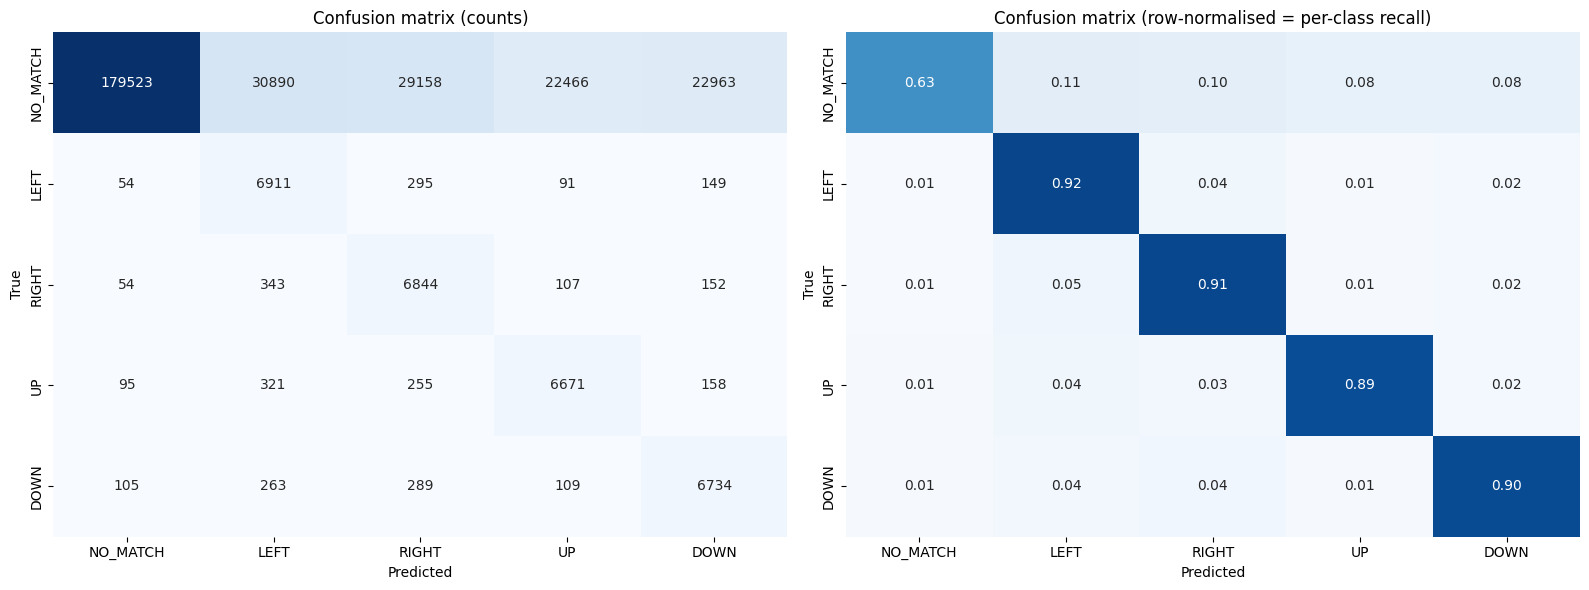


--- Per-image summary ---


image,pairs,top1_acc,top3_acc,relationships_total,relationships_correct_top1,relationship_acc_top1,relationships_correct_top3,false_adjacent_pred
000000007386.jpg,1260,69.05%,98.89%,120,110,91.67%,118,380
000000011051.jpg,1260,72.62%,99.44%,120,111,92.50%,119,336
000000011197.jpg,1260,62.62%,97.78%,120,112,93.33%,119,463
000000011760.jpg,1260,35.24%,86.27%,120,111,92.50%,120,807
000000015751.jpg,1260,67.54%,99.37%,120,118,98.33%,120,407
000000023899.jpg,1260,18.17%,47.46%,120,82,68.33%,113,993
000000025986.jpg,1260,87.38%,100.00%,120,119,99.17%,120,158
000000030504.jpg,1260,72.86%,99.68%,120,116,96.67%,120,338
000000031269.jpg,1260,67.78%,93.33%,120,104,86.67%,119,390
000000035197.jpg,1260,63.02%,97.94%,120,105,87.50%,118,451


Mean per-image top-1 acc: 65.61% | mean relationship acc: 90.53%

Saved CSVs and confusion matrix to: /content/drive/MyDrive/Jigsaw_Puzzle_Project/eval_results


In [ ]:
y_true = pairs_df["true"].to_numpy()
y_pred = pairs_df["top1"].to_numpy()
top3_hit = pairs_df[f"top{TOP_K}_correct"].to_numpy()
adj = y_true != NO_MATCH

cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
recall_per_class = np.divide(np.diag(cm), cm.sum(axis=1), out=np.full(NUM_CLASSES, np.nan), where=cm.sum(axis=1) > 0)

print("=" * 60)
print("OVERALL RESULTS")
print("=" * 60)
print(f"Images evaluated            : {len(images_df)}")
print(f"Pairs evaluated             : {len(pairs_df)}")
print(f"Top-1 accuracy (all pairs)  : {(y_true == y_pred).mean():.2%}")
print(f"Top-{TOP_K} accuracy (all pairs)  : {top3_hit.mean():.2%}")
print(f"Balanced accuracy (mean recall over classes): {np.nanmean(recall_per_class):.2%}")
print(f"Macro F1 / Weighted F1      : {f1_score(y_true, y_pred, average='macro', labels=CLASS_IDS, zero_division=0):.4f} / "
      f"{f1_score(y_true, y_pred, average='weighted', labels=CLASS_IDS, zero_division=0):.4f}")
print(f"\nTrue adjacent relationships correctly recovered (top-1): "
      f"{int(((y_true == y_pred) & adj).sum())}/{int(adj.sum())} "
      f"({((y_true == y_pred) & adj).sum() / adj.sum():.2%})")
print(f"  ... within top-{TOP_K}: {int((top3_hit & adj).sum())}/{int(adj.sum())} ({(top3_hit & adj).sum() / adj.sum():.2%})")
print("\nNote: NO_MATCH dominates the pairs, so overall accuracy alone is optimistic; "
      "look at balanced accuracy and the per-class table below.")

# ---- Per-class report (precision / recall / F1) ----
print("\n--- Classification report (top-1) ---")
print(classification_report(y_true, y_pred, labels=CLASS_IDS, target_names=CLASS_STR, digits=4, zero_division=0))

# ---- Per-class top-1 / top-3 ----
overall_class_df = per_class_table(y_true, y_pred, top3_hit)
display(overall_class_df.style.format({"top1_acc": "{:.2%}", f"top{TOP_K}_acc": "{:.2%}"}).hide(axis="index"))

# ---- Confusion matrix (counts + row-normalised) ----
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASS_STR, yticklabels=CLASS_STR, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
            xticklabels=CLASS_STR, yticklabels=CLASS_STR, ax=axes[1])
axes[1].set_title("Confusion matrix (row-normalised = per-class recall)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
if OUTPUT_DIR:
    plt.savefig(os.path.join(OUTPUT_DIR, f"confusion_matrix_grid{GRID_SIZE}.png"), dpi=150, bbox_inches="tight")
plt.show()

# ---- Per-image summary ----
print("\n--- Per-image summary ---")
display(images_df.style.format({
    "top1_acc": "{:.2%}", f"top{TOP_K}_acc": "{:.2%}", "relationship_acc_top1": "{:.2%}"}).hide(axis="index"))
print(f"Mean per-image top-1 acc: {images_df['top1_acc'].mean():.2%} | "
      f"mean relationship acc: {images_df['relationship_acc_top1'].mean():.2%}")

# ---- Save ----
if OUTPUT_DIR:
    pairs_df.to_csv(os.path.join(OUTPUT_DIR, f"pair_predictions_grid{GRID_SIZE}.csv"), index=False)
    images_df.to_csv(os.path.join(OUTPUT_DIR, f"per_image_summary_grid{GRID_SIZE}.csv"), index=False)
    overall_class_df.to_csv(os.path.join(OUTPUT_DIR, f"per_class_summary_grid{GRID_SIZE}.csv"), index=False)
    print(f"\nSaved CSVs and confusion matrix to: {OUTPUT_DIR}")